 ## Dataset Attributes

 The dataset contains information about houses in Ames, Iowa. The data was collected by the Ames City Assessor’s Office describing 2930 property sales which occurred in Ames, Iowa between 2006 and 2010. The dataset, containing 81 variables, was compiled and published by De Cock in 2011.

 Some of the variables contained in the original dataset have been removed from the the dataset provided to you.
 The dataset provided to you contains the following variables:
* **Year_Built:** year that the house was originally constructed
* **Year_Remod_Add:** year that the house was last remodelled
* **Total_Bsmt_SF:** total size of basement area in square feet
* **First_Flr_SF:** size of the first floor in square feet
* **Second_Flr_SF:** size of the second floor in square feet
* **Gr_Liv_Area:** size of above grade, ground living area in square feet
* **Full_Bath:** number of full above grade bathrooms in the house
* **Half_Bath:** number of half above grade bathrooms in the house
* **Bedroom_AbvGr:** number of above grade bedrooms (does not include basement bedrooms)
* **Kitchen_AbvGr:** number of above grade kitchens
* **TotRms_AbvGrd:** total number of above grade rooms (does not include bathrooms)
* **Fireplaces:** number of fireplaces in the house
* **Garage_Area:** size of garage in square feet
* **Sale_Price:** sale price of the house in dollars


*De Cock, D. (2011). "Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester
Regression Project," Journal of Statistics Education, Volume 19, Number 3.*

- https://ww2.amstat.org/publications/jse/v19n3/decock/DataDocumentation.txt
- http://ww2.amstat.org/publications/jse/v19n3/decock.pdf


# Predicting Sales Prices

 ## Objective

 The goal of this task is to analyse the relationship between these variables and build a multiple linear regression model to predict the sales prices based on the 'Gr_Liv_Area' and 'Garage_Area` variables.


In [15]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import statsmodels.api as sm

# Ensures the same random data is used each time you execute the code
np.random.seed(0)




In [16]:
# Read in the data set
ames_data = pd.read_csv('ames.csv', index_col=0)
ames_data.head()

,Year_Remod_Add,Total_Bsmt_SF,First_Flr_SF,Second_Flr_SF,Gr_Liv_Area,Full_Bath,Half_Bath,Bedroom_AbvGr,Kitchen_AbvGr,TotRms_AbvGrd,Fireplaces,Garage_Area,Sale_Price
Year_Built,,,,,,,,,,,,,
1960,1960,1080,1656,0,1656,1,0,3,1,7,2,528,215000
1961,1961,882,896,0,896,1,0,2,1,5,0,730,105000
1958,1958,1329,1329,0,1329,1,1,3,1,6,0,312,172000
1968,1968,2110,2110,0,2110,2,1,3,1,8,2,522,244000
1997,1998,928,928,701,1629,2,1,3,1,6,1,482,189900


Working with missing data

This is the first step during any data analysis. Depending on the data sources, missing data are identified diffently. Pandas identifies missing values as NaN. Missing values can appear as question (?) or a zero (0) or minus one (-1) or a blank. So it is important to view and understand the data before anything else.

To start lets check the dimension of the DataFrame to understand its size and then preview the first few rows to a get a sense of the data

In [17]:
# Clean and pre-process the data if neccessary
# Return the number of rows and columns of the DataFrame
ames_data.shape

(2930, 13)

How many NaN or missing values in the dataset. We are going to find how many missing values we have in each column

In [18]:
# Get the number of missing data values per column
missing_values_count = ames_data.isnull().sum()

# Look at the number of missing values in the 13 columns
missing_values_count[0:14]

Year_Remod_Add    0
Total_Bsmt_SF     0
First_Flr_SF      0
Second_Flr_SF     0
Gr_Liv_Area       0
Full_Bath         0
Half_Bath         0
Bedroom_AbvGr     0
Kitchen_AbvGr     0
TotRms_AbvGrd     0
Fireplaces        0
Garage_Area       0
Sale_Price        0
dtype: int64

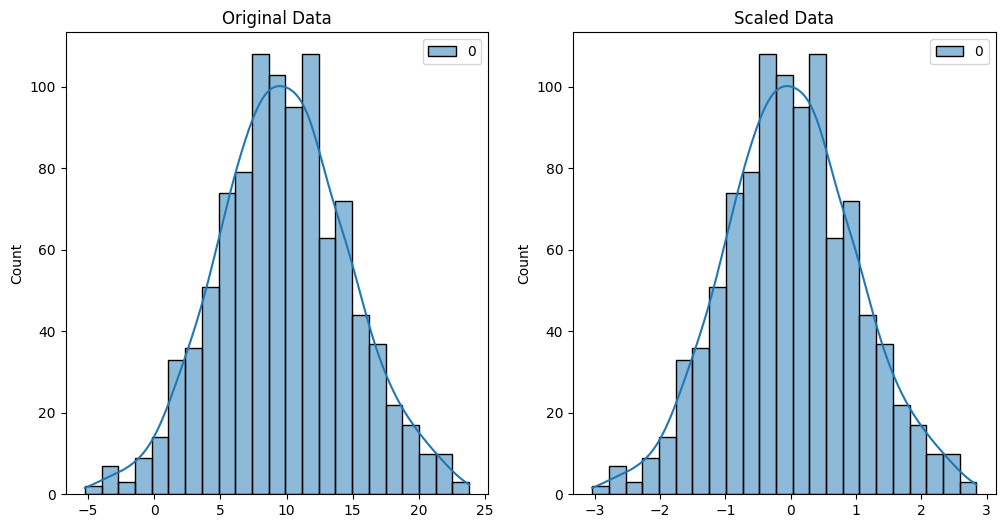

In [19]:
# Explore the data with visualisations such as histograms and correlation matrices
# Generate 1000 data points randomly drawn from a normal distribution
original_ames_data = np.random.normal(loc=10, scale=5, size=1000).reshape(-1, 1)

# Create the StandardScaler object
scaler = StandardScaler()

# Fit the scaler to the data and transform it
scaled_data = scaler.fit_transform(original_ames_data)

# Plot the original and scaled data to compare
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

sns.histplot(original_ames_data, ax=ax[0], kde=True)
ax[0].set_title("Original Data")

sns.histplot(scaled_data, ax=ax[1], kde=True)
ax[1].set_title("Scaled Data")

plt.show()

In [20]:
# Split the independent variables from the dependent variable
X = ames_data[["Year_Remod_Add", "Total_Bsmt_SF", "First_Flr_SF", "Second_Flr_SF", "Gr_Liv_Area",
               "Bedroom_AbvGr", "Kitchen_AbvGr", "TotRms_AbvGrd", "Fireplaces", "Garage_Area"]]

y = ames_data["Sale_Price"]

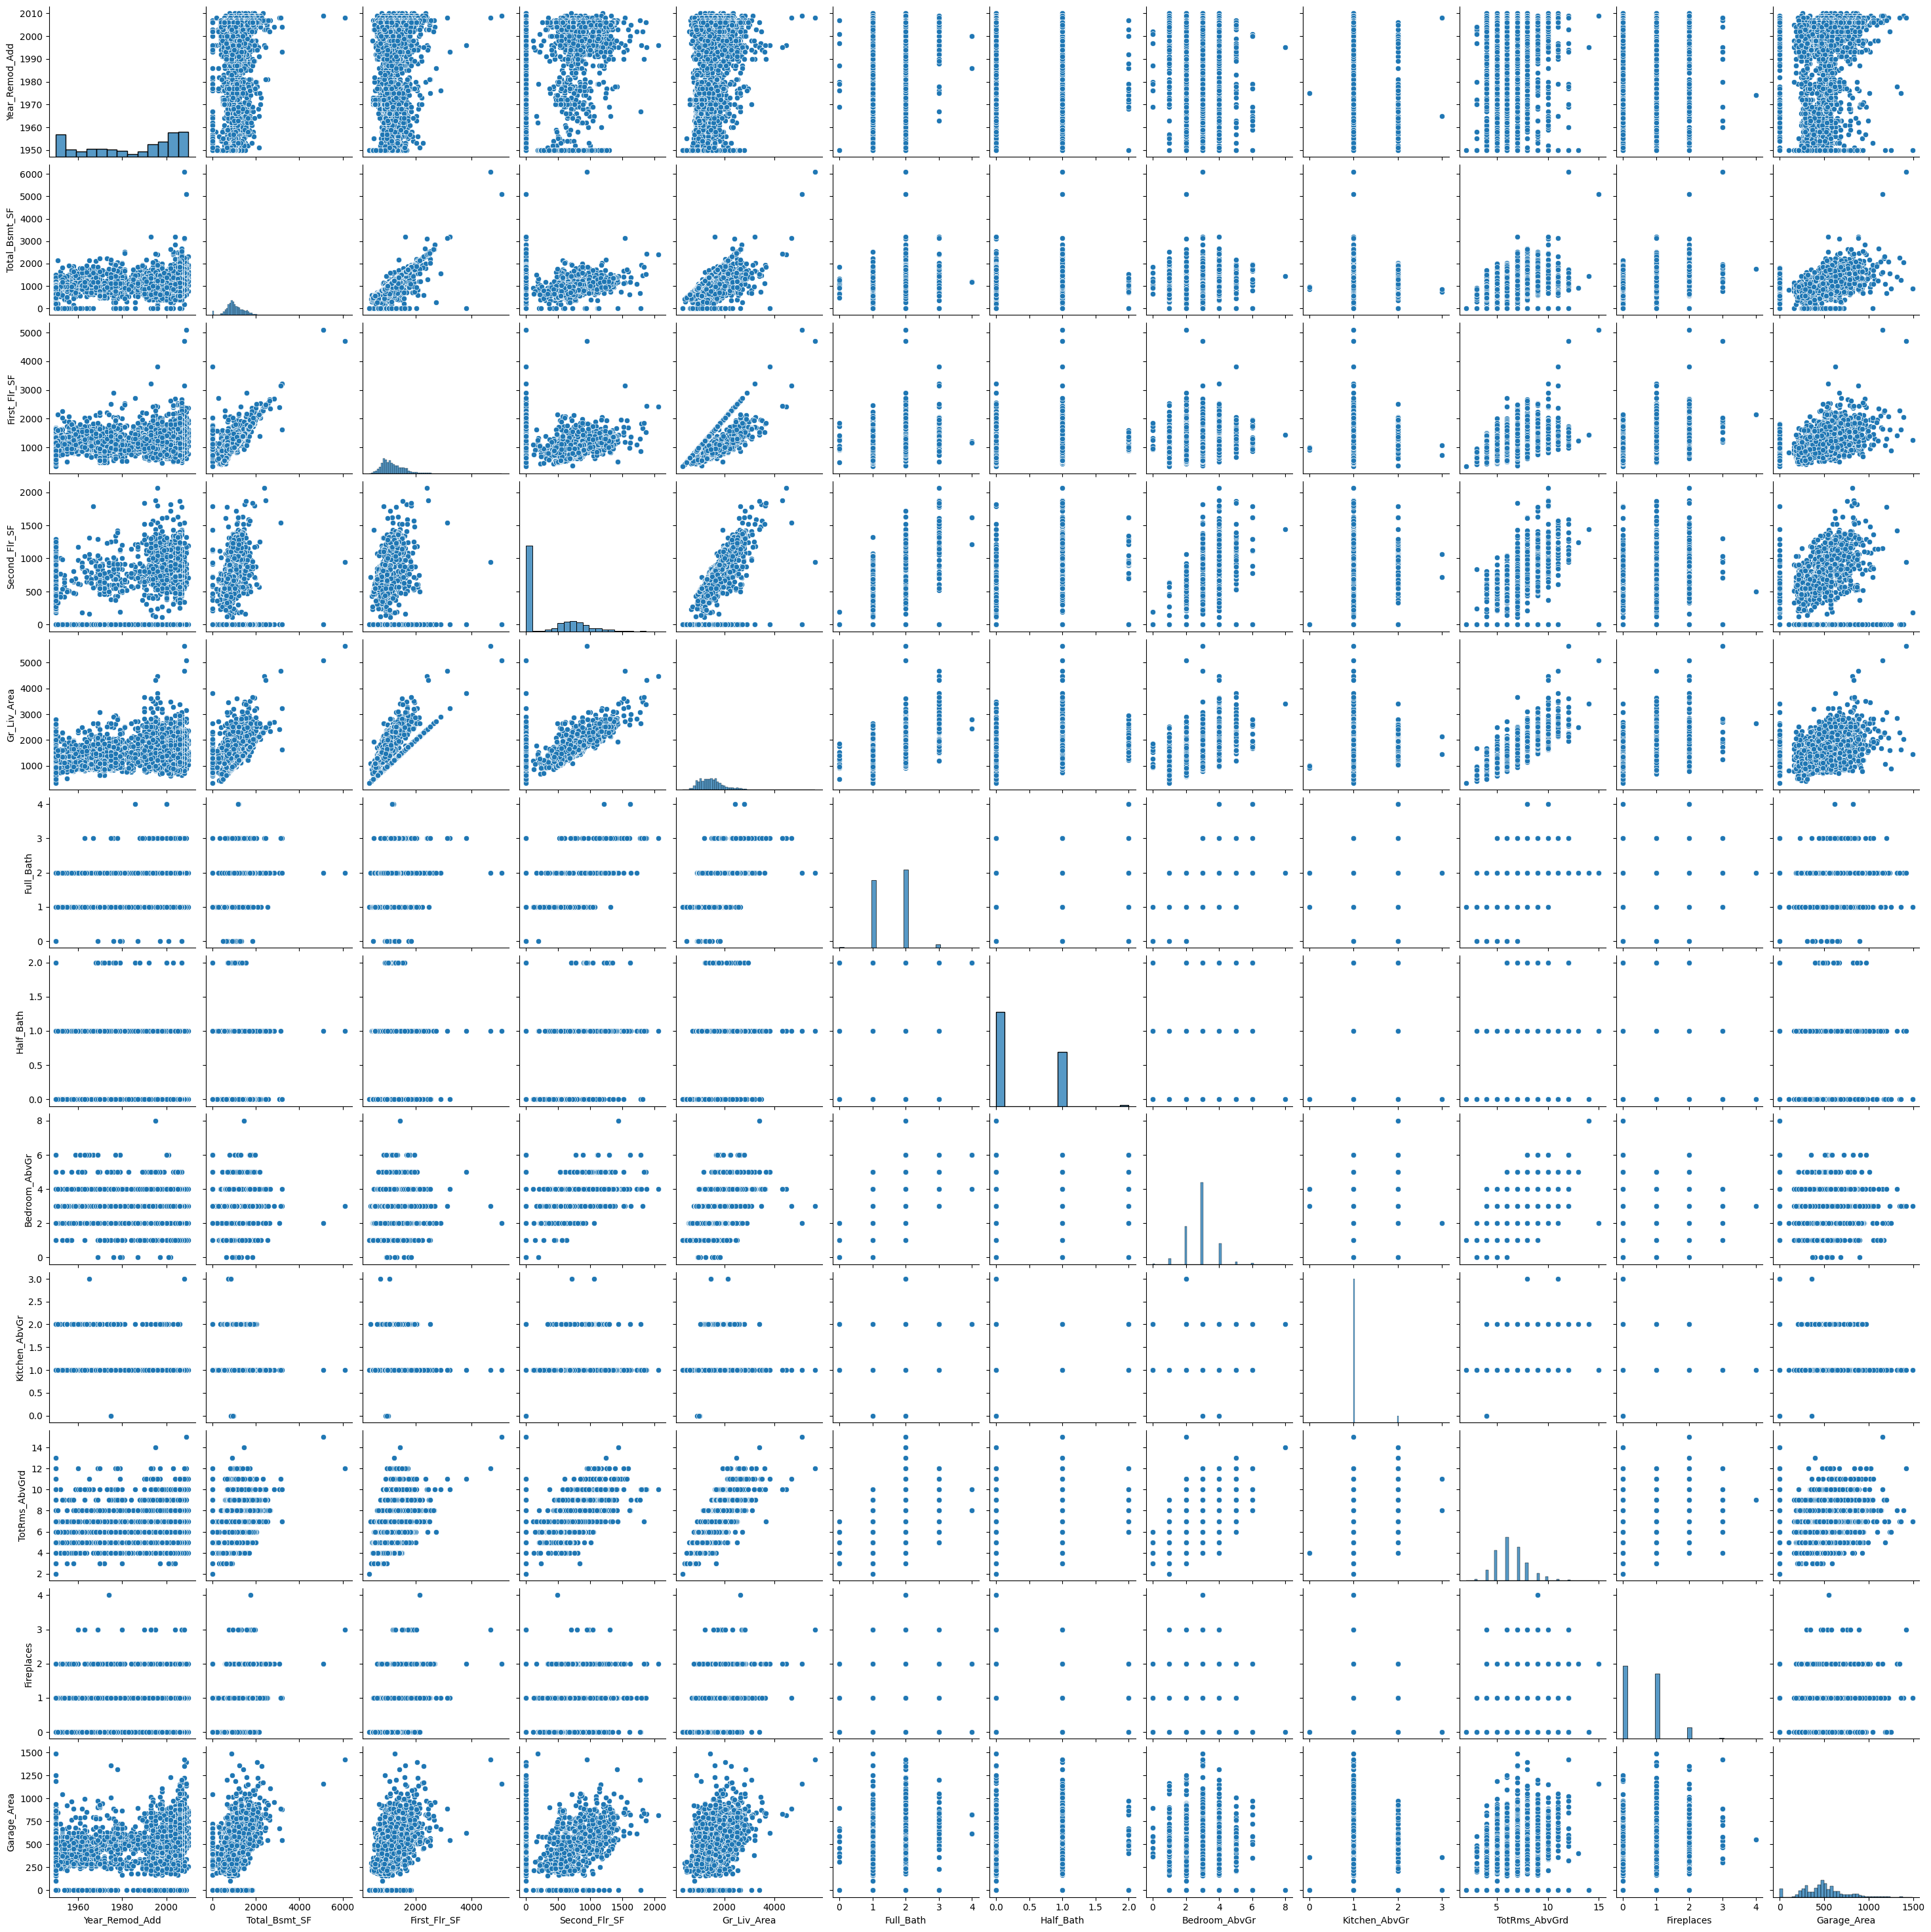

In [21]:
# Generate plots to explore the relationships between the independent and dependent variables
sns.pairplot(data=ames_data.drop('Sale_Price', axis=1))




In [22]:
# Create a training and test set with a 75:25 split ratio
# Split the data into training and test sets
rseed = 23 # use the same random seed for learning purposes to get the same results
X_train, X_test, y_train, Y_test = train_test_split(X, y, test_size=0.25, random_state=rseed)

print("Training data: ", X_train.shape, y_train.shape)
print("Test data: ", X_test.shape, Y_test.shape)


Training data:  (2197, 10) (2197,)
Test data:  (733, 10) (733,)


In [23]:
# Build a multiple linear regression model using 'Gr_Liv_Area' and 'Garage_Area'
# Features
X = ames_data.loc[:, ["Gr_Liv_Area", "Garage_Area"]]
y = ames_data["Sale_Price"]

# Create an empty Linear Regression model
ames_model = LinearRegression()

# Create the model using fit(X, y)
ames_model.fit(X, y)







,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [24]:
# Print the trained model's intercept and coefficients
# Get intercept and coefficients
print('Intercept: \n', ames_model.intercept_)
print('Coefficients: \n', ames_model.coef_)

Intercept: 
 -10365.251585966005
Coefficients: 
 [ 81.92294905 144.50658946]


Let us normalise our data using MinMaxScaler. Please note that we fit it on the training set

In [25]:
# Generate predictions for the test set
# Fit the scaler on the train data
sc = MinMaxScaler()
sc.fit(X_train)

# Apply the scaler on the train and test data
X_train = sc.transform(X_train)
X_test = sc.transform(X_test)

# Fit the model on the training data
lm = LinearRegression()
ames_model = lm.fit(X_train, y_train)
predictions = lm.predict(X_test)

# Create line coordinates
X_line = np.empty(X_test.shape)
for i in range(X_test.shape[1]):
    X_line[:, i] = np.linspace(np.min(X_test[:,i]), np.max(X_test[:,i]), num=X_test.shape[0])
y_line = lm.predict(X_line)

print('Intercept: \n', lm.intercept_)
print('Coefficients: \n', lm.coef_)

# Predictions for the test set
predictions[0:12]


Intercept: 
 54841.431309362844
Coefficients: 
 [  46497.17653212  250787.10432292  366375.51584381  167004.43519889
   -7117.35049532 -106513.60157885 -115126.94004748   18670.67723119
   38810.72037144   96386.7470399 ]


array([ 82055.41420034, 186279.87063818, 158286.70694884,  70498.68421362,
       349477.26417874, 230820.71791932, 249696.61524851, 280254.8656502 ,
       236475.248196  , 189194.52145494, 129027.20190666, 147819.19145642])

In [26]:
# Evaluate the model's performance by computing the mean squared error (MSE) or root mean squared error (RMSE) on the test set using sklearn.metrics.
# Define features and target
X = ames_data.drop(columns=["Sale_Price"])
y = ames_data["Sale_Price"]

# Convert categorical features into numerical format
X = pd.get_dummies(X, drop_first=True)

# Split dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create and train model
ames_model = RandomForestRegressor(random_state=42)
ames_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = ames_model.predict(X_test)

# Compute the RMSE
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Show result
print(f"The Root Mean Squared Error (RMSE): ", rmse)


The Root Mean Squared Error (RMSE):  31210.803107018994


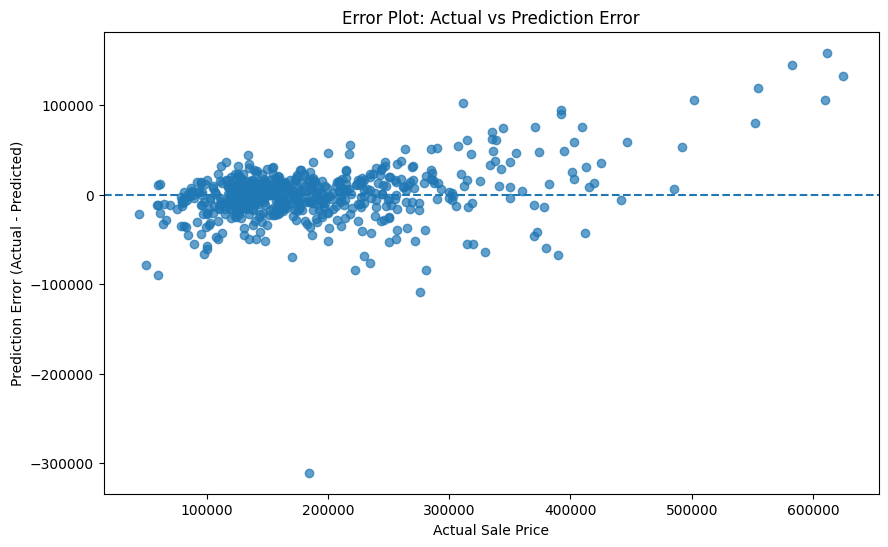

In [27]:
# Generate an error plot to visualise the differences between the predicted and actual values in the test set.
# Create error values
errors = y_test - y_pred

# Plot prediction errors
plt.figure(figsize=(10, 6))
plt.scatter(y_test, errors, alpha=0.7)
plt.axhline(y=0, linestyle='--')

# Labels and title
plt.xlabel("Actual Sale Price")
plt.ylabel("Prediction Error (Actual - Predicted)")
plt.title("Error Plot: Actual vs Prediction Error")

# Show plot
plt.show()


In [29]:
# Print the coefficients and interpret them within the context of the median value prediction.
# Define target variable
target = "Sale_Price"
X = ames_data.drop(columns=[target])
y = ames_data[target]

# Define numeric and categorical columns
numeric_columns = X.select_dtypes(include=["int64", "float64"]).columns
categorical_columns = X.select_dtypes(include=["object"]).columns

# Preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_columns),
        ("categorical", categorical_transformer, categorical_columns)

    ],
    remainder="drop"
)

# test and train set split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Building model pipeline
ames_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train the model
ames_model.fit(X_train, y_train)

# Predict and evaluate
y_pred = ames_model.predict(X_test)

#print("R squared Score:", round(r2_score(y_test, y_pred), 3))
print("Mean squared error:", round(mean_squared_error(y_test, y_pred), 2))

# Extract coefficients
feature_names = numeric_columns

coefficients = ames_model.named_steps["regressor"].coef_

coef_ames_data = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by absolute importance
coef_ames_data["AbsCoeff"] = coef_ames_data["Coefficient"].abs()
coef_ames_data = coef_ames_data.sort_values(by="AbsCoeff", ascending=False)

print("\nTop Coefficients: \n")
print(coef_ames_data[["Feature", "Coefficient"]].head(10))

# Interpret coefficients
print("\nInterpretation:\n")

for _, row in coef_ames_data.head(10).iterrows():
    feature = row["Feature"]
    coef = row["Coefficient"]

    if coef > 0:
        direction = "increases"
    else:
        direction = "decreases"

    print (
        f" - A 1 standard deviation increases in '{feature}' "
        f"{direction} the predicted house price by approximately "
        f"{abs(coef):.2f} units (holding other variables constant)."
    )

Mean squared error: 1638046812.88

Top Coefficients: 

           Feature   Coefficient
3    Second_Flr_SF  30143.978229
2     First_Flr_SF  28969.163408
1    Total_Bsmt_SF  17256.300619
0   Year_Remod_Add  14736.328420
11     Garage_Area  14131.664194
7    Bedroom_AbvGr  -9023.506338
8    Kitchen_AbvGr  -8626.871738
10      Fireplaces   7475.299545
4      Gr_Liv_Area  -6341.238437
5        Full_Bath   6184.344586

Interpretation:

 - A 1 standard deviation increases in 'Second_Flr_SF' increases the predicted house price by approximately 30143.98 units (holding other variables constant).
 - A 1 standard deviation increases in 'First_Flr_SF' increases the predicted house price by approximately 28969.16 units (holding other variables constant).
 - A 1 standard deviation increases in 'Total_Bsmt_SF' increases the predicted house price by approximately 17256.30 units (holding other variables constant).
 - A 1 standard deviation increases in 'Year_Remod_Add' increases the predicted house pr

**Interpret coefficients in the context of the prediction:**
The coefficients correlate with the predictions. The values that are in the coefficients are similar to the predicted houses prices

**Summarise findings**
A 1 standard deviation increase in any house feature increases the predicted house prices.